Objectif : On voit la viscosité $\nu$ comme une variable i.e 
$$
u = u(t,x,\nu)
$$
pour entrainer le PINN sur plusieurs viscosité

# Import

In [3]:
import tensorflow as tf
import numpy as np
import copy as cp
import scipy.sparse.linalg as linalg
import matplotlib.pyplot as plt
from time import time
import scipy.optimize

gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

# Paramètres du problème

par rapport aux PINN classique on a rajouté une dimension aux variables qui correspond à la viscosité

In [4]:
# Set data type
DTYPE='float32'
tf.keras.backend.set_floatx(DTYPE)

# Set constants
pi = tf.constant(np.pi, dtype=DTYPE)

# Set boundary
tmin = 0.
tmax = 1.
xmin = -1.
xmax = 1.

numin = 1e-3
numax=  1e-2

# Lower bounds
lb = tf.constant([tmin, xmin, numin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax, numax], dtype=DTYPE)

# Define initial condition
def fun_u_0(x):
    return -tf.sin(pi * x)

# Define boundary condition
def fun_u_b(t, x):
    n = x.shape[0]
    return tf.zeros((n,1), dtype=DTYPE)

# données d'entrainement

In [5]:
def gen_train_data(N_0=1000, N_b=1000, N_r=10000):

  # Set random seed for reproducible results
  tf.random.set_seed(0)

  # Draw uniform sample points for initial boundary data
  t_0 = tf.ones((N_0,1), dtype=DTYPE)*lb[0]
  x_0 = tf.random.uniform((N_0,1), lb[1], ub[1], dtype=DTYPE)
  nu_0 = tf.random.uniform((N_0,1), lb[2], ub[2], dtype=DTYPE)
  X_0 = tf.concat([t_0, x_0, nu_0], axis=1)

  # Evaluate intitial condition at x_0
  u_0 = fun_u_0(x_0)

  # Boundary data
  t_b = tf.random.uniform((N_b,1), lb[0], ub[0], dtype=DTYPE)
  x_b = lb[1] + (ub[1] - lb[1]) * tf.keras.backend.random_bernoulli((N_b,1), 0.5, dtype=DTYPE)
  nu_b = tf.random.uniform((N_b,1), lb[2], ub[2], dtype=DTYPE)
  X_b = tf.concat([t_b, x_b, nu_b], axis=1)

  # Evaluate boundary condition at (t_b,x_b)
  u_b = fun_u_b(t_b, x_b)

  # Draw uniformly sampled collocation points
  t_r = tf.random.uniform((N_r,1), lb[0], ub[0], dtype=DTYPE)
  x_r = tf.random.uniform((N_r,1), lb[1], ub[1], dtype=DTYPE)
  nu_r = tf.random.uniform((N_r,1), lb[2], ub[2], dtype=DTYPE)
  X_r = tf.concat([t_r, x_r, nu_r], axis=1)

  # Collect boundary and inital data in lists
  X_data = [X_0, X_b]
  u_data = [u_0, u_b]

  return X_r, X_data, u_data

In [6]:
X_r, X_data, u_data = gen_train_data(10_000, 10_000, 100_000)

## PINN model

In [7]:
class PhysicsInformedNN(tf.keras.Model):
    """ Set basic architecture of the PINN model."""

    def __init__(self, lb, ub, 
            output_dim=1,
            num_hidden_layers=8, 
            num_neurons_per_layer=20,
            activation='tanh',
            kernel_initializer='glorot_normal',
            **kwargs):
        super().__init__(**kwargs)

        self.num_hidden_layers = num_hidden_layers
        self.output_dim = output_dim
        self.lb = lb
        self.ub = ub
        
        # Define NN architecture
        self.scale = tf.keras.layers.Lambda(
            lambda x: 2.0*(x - lb)/(ub - lb) - 1.0)
        self.hidden = [tf.keras.layers.Dense(num_neurons_per_layer,
                             activation=tf.keras.activations.get(activation),
                             kernel_initializer=kernel_initializer)
                           for _ in range(self.num_hidden_layers)]
        self.out = tf.keras.layers.Dense(output_dim)
        
    def call(self, X):
        """Forward-pass through neural network."""
        Z = self.scale(X)
        for i in range(self.num_hidden_layers):
            Z = self.hidden[i](Z)
        return self.out(Z)
  


In [8]:
class PINNSolver():
    def __init__(self, model, X_r):
        self.model = model
        
        # Store collocation points
        self.t = X_r[:,0:1]
        self.x = X_r[:,1:2]
        self.nu = X_r[:,2:3]
        
        # Initialize history of losses and global iteration counter
        self.hist = []
        self.iter = 0
    
    def get_r(self):
        
        with tf.GradientTape(persistent=True) as tape:
            # Watch variables representing t and x during this GradientTape
            tape.watch(self.t)
            tape.watch(self.x)
        
            # Compute current values u(t,x)
            u = self.model(tf.stack([self.t[:,0], self.x[:,0], self.nu[:,0]], axis=1))
            
            u_x = tape.gradient(u, self.x)
            
        u_t = tape.gradient(u, self.t)
        u_xx = tape.gradient(u_x, self.x)
        
        del tape
        
        return self.fun_r(self.t, self.x, self.nu, u, u_t, u_x, u_xx)
    
    def loss_fn(self, X, u):
        
        # Compute phi_r
        r = self.get_r()
        phi_r = tf.reduce_mean(tf.square(r))
        
        # Initialize loss
        loss = phi_r

        # Add phi_0 and phi_b to the loss
        for i in range(len(X)):
            u_pred = self.model(X[i])
            loss += tf.reduce_mean(tf.square(u[i] - u_pred))
        
        return loss
    
    def get_grad(self, X, u):
        with tf.GradientTape(persistent=True) as tape:
            # This tape is for derivatives with
            # respect to trainable variables
            tape.watch(self.model.trainable_variables)
            loss = self.loss_fn(X, u)
            
        g = tape.gradient(loss, self.model.trainable_variables)
        del tape
        
        return loss, g
    
    def fun_r(self, t, x, nu, u, u_t, u_x, u_xx):
        """Residual of the PDE"""
        return u_t + u * u_x - nu * u_xx

    def solve_with_TFoptimizer(self, optimizer, X, u, N=1001):
        """This method performs a gradient descent type optimization."""
        
        @tf.function
        def train_step():
            loss, grad_theta = self.get_grad(X, u)
            
            # Perform gradient descent step
            optimizer.apply_gradients(zip(grad_theta, self.model.trainable_variables))
            return loss
        
        for i in range(N):
            
            loss = train_step()
            
            self.current_loss = loss.numpy()
            self.callback()
    
    def solve_with_ScipyOptimizer(self, X, u, method='L-BFGS-B'):
        
        def get_weight_tensor():
            """Function to return current variables of the model
            as 1d tensor as well as corresponding shapes as lists."""
            
            weight_list = []
            shape_list = []
            
            # Loop over all variables, i.e. weight matrices, bias vectors and unknown parameters
            for v in self.model.variables:
                shape_list.append(v.shape)
                weight_list.extend(v.numpy().flatten())
                
            weight_list = tf.convert_to_tensor(weight_list)
            return weight_list, shape_list

        x0, shape_list = get_weight_tensor()
        
        def set_weight_tensor(weight_list):
            """Function which sets list of weights
            to variables in the model."""
            idx = 0
            for v in self.model.variables:
                vs = v.shape
                
                # Weight matrices
                if len(vs) == 2:  
                    sw = vs[0]*vs[1]
                    new_val = tf.reshape(weight_list[idx:idx+sw],(vs[0],vs[1]))
                    idx += sw
                
                # Bias vectors
                elif len(vs) == 1:
                    new_val = weight_list[idx:idx+vs[0]]
                    idx += vs[0]
                    
                # Variables (in case of parameter identification setting)
                elif len(vs) == 0:
                    new_val = weight_list[idx]
                    idx += 1
                    
                # Assign variables (Casting necessary since scipy requires float64 type)
                v.assign(tf.cast(new_val, DTYPE))
        
        def get_loss_and_grad(w):
            """Function that provides current loss and gradient
            w.r.t the trainable variables as vector. This is mandatory
            for the LBFGS minimizer from scipy."""
            
            # Update weights in model
            set_weight_tensor(w)
            # Determine value of \phi and gradient w.r.t. \theta at w
            loss, grad = self.get_grad(X, u)
            
            # Store current loss for callback function            
            loss = loss.numpy().astype(np.float64)
            self.current_loss = loss            
            
            # Flatten gradient
            grad_flat = []
            for g in grad:
                grad_flat.extend(g.numpy().flatten())
            
            # Gradient list to array
            grad_flat = np.array(grad_flat,dtype=np.float64)
            
            # Return value and gradient of \phi as tuple
            return loss, grad_flat
        
        
        return scipy.optimize.minimize(fun=get_loss_and_grad,
                                       x0=x0,
                                       jac=True,
                                       method=method,
                                       callback=self.callback,
                                       options={'maxiter': 3000,
                                                'maxfun': 50000,
                                                'maxcor': 50,
                                                'maxls': 50,
                                                'ftol': 1.0*np.finfo(float).eps})
        
    def callback(self, xr=None):
        if self.iter % 100 == 0:
            print('Iteration {:05d}: loss = {:10.8e}'.format(self.iter,self.current_loss))
        self.hist.append(self.current_loss)
        self.iter+=1
                
    def plot_loss_history(self, ax=None):

        if not ax:
            fig = plt.figure(figsize=(7,5))
            ax = fig.add_subplot(111)

        ax.semilogy(range(len(self.hist)), self.hist,'k-')
        ax.set_xlabel('$Iteration$')
        ax.set_ylabel('Loss')
        ax.legend()

        return ax

In [9]:
model = PhysicsInformedNN(lb, ub, num_hidden_layers=8, num_neurons_per_layer=20)
model.build(input_shape=(None,3))

# Initilize PINN solver
solver = PINNSolver(model, X_r)

model.summary()

Model: "physics_informed_nn"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
lambda (Lambda)              multiple                  0         
_________________________________________________________________
dense (Dense)                multiple                  80        
_________________________________________________________________
dense_1 (Dense)              multiple                  420       
_________________________________________________________________
dense_2 (Dense)              multiple                  420       
_________________________________________________________________
dense_3 (Dense)              multiple                  420       
_________________________________________________________________
dense_4 (Dense)              multiple                  420       
_________________________________________________________________
dense_5 (Dense)              multiple          

In [10]:
t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=1000,
    decay_rate=0.96,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_data, u_data, N=4001)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 00000: loss = 6.03603423e-01
Iteration 00100: loss = 1.50102824e-01
Iteration 00200: loss = 1.21852055e-01
Iteration 00300: loss = 1.07694007e-01
Iteration 00400: loss = 9.38478187e-02
Iteration 00500: loss = 8.41962919e-02
Iteration 00600: loss = 7.74303079e-02
Iteration 00700: loss = 6.72373474e-02
Iteration 00800: loss = 6.36121184e-02
Iteration 00900: loss = 4.81137410e-02
Iteration 01000: loss = 4.02153507e-02
Iteration 01100: loss = 3.35293300e-02
Iteration 01200: loss = 2.90514398e-02
Iteration 01300: loss = 2.54649892e-02
Iteration 01400: loss = 2.30863728e-02
Iteration 01500: loss = 2.73652021e-02
Iteration 01600: loss = 1.84319988e-02
Iteration 01700: loss = 1.67516656e-02
Iteration 01800: loss = 1.62289161e-02
Iteration 01900: loss = 1.47100855e-02
Iteration 02000: loss = 1.24344574e-02
Iteration 02100: loss = 1.21736601e-02
Iteration 02200: loss = 1.03877503e-02
Iteration 02300: loss = 9.46520548e-03
Iteration 02400: loss = 8.69107805e-03
Iteration 02500: loss = 7

In [16]:
t0 = time()
try: 
  solver.solve_with_ScipyOptimizer(X_data, u_data)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))


Training time: 1.469313144683838 seconds


In [18]:
N = 1000
T = 0.5 * np.ones(N+1)
xspace = np.linspace(lb[1], ub[1], N + 1)
nuspace = numin * np.ones(N+1)
Xgrid = np.vstack([T.flatten(),xspace.flatten(), nuspace.flatten()]).T
upred = model(tf.cast(Xgrid,DTYPE))

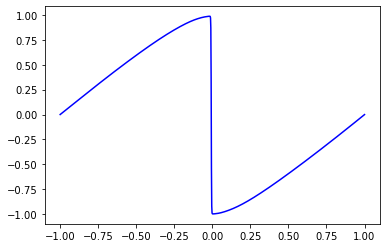

In [19]:
plt.plot(xspace,upred, 'b-')

No handles with labels found to put in legend.


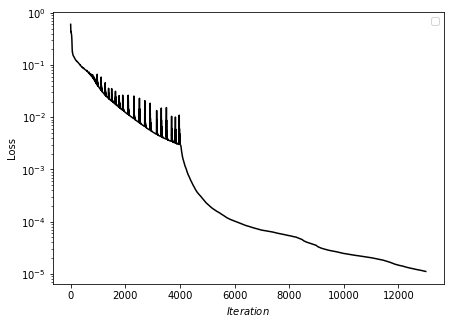

In [23]:
solver.plot_loss_history();

# vérification que ca fonctionne 

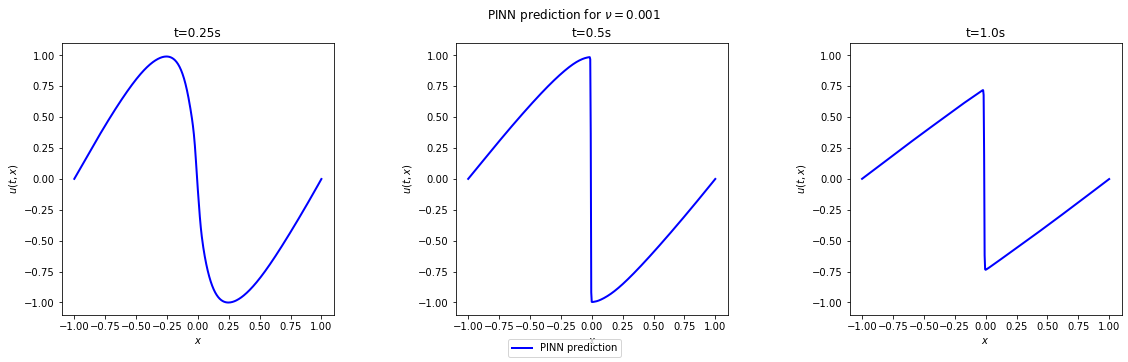

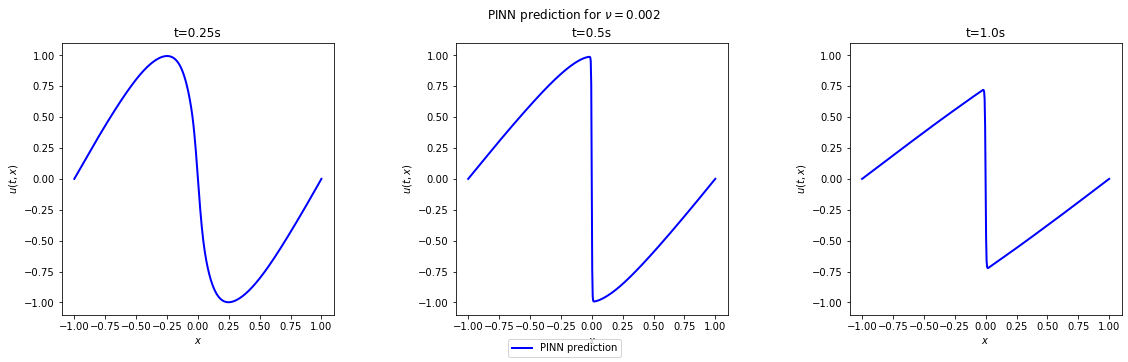

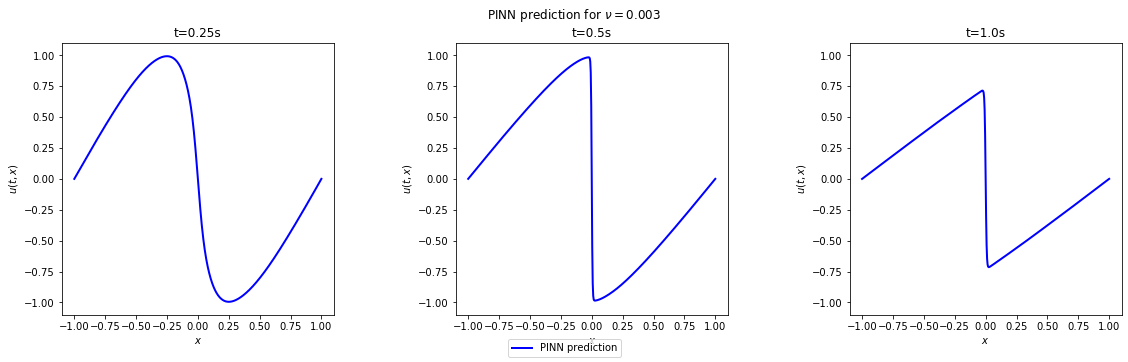

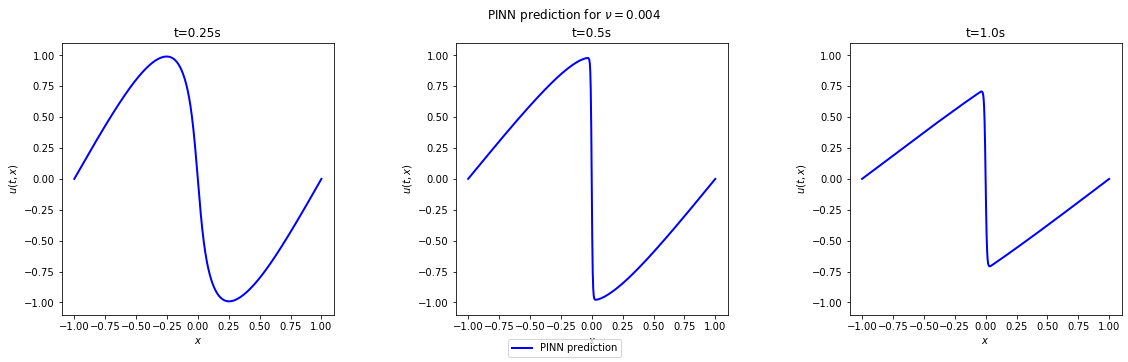

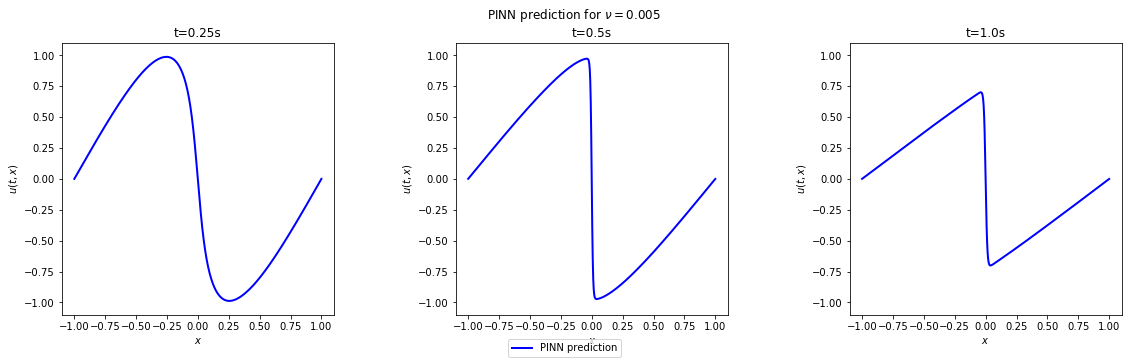

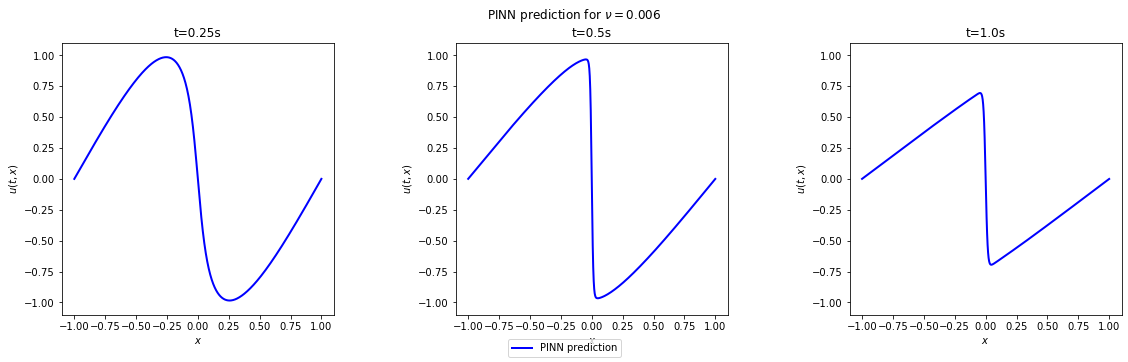

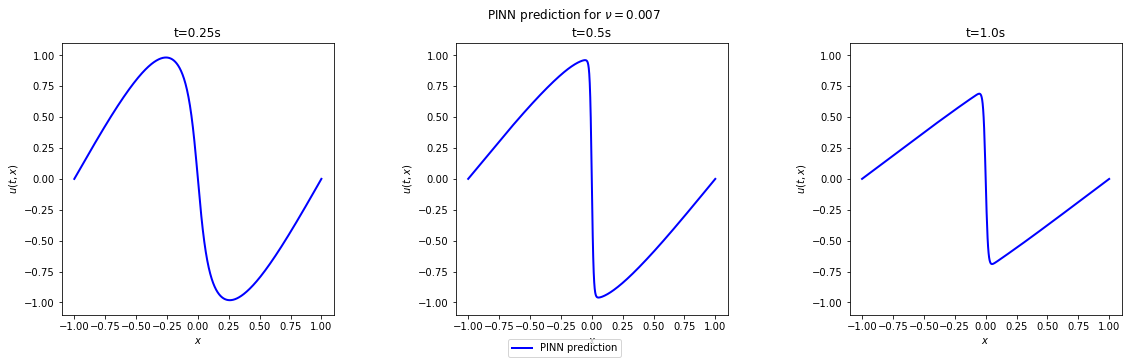

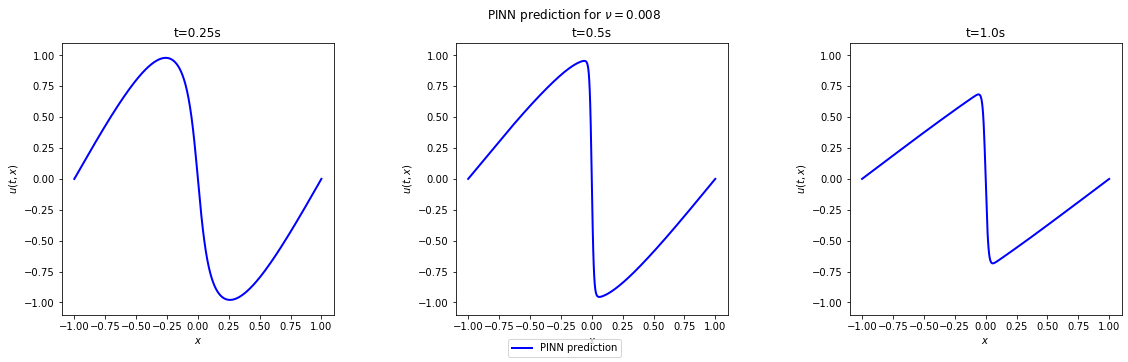

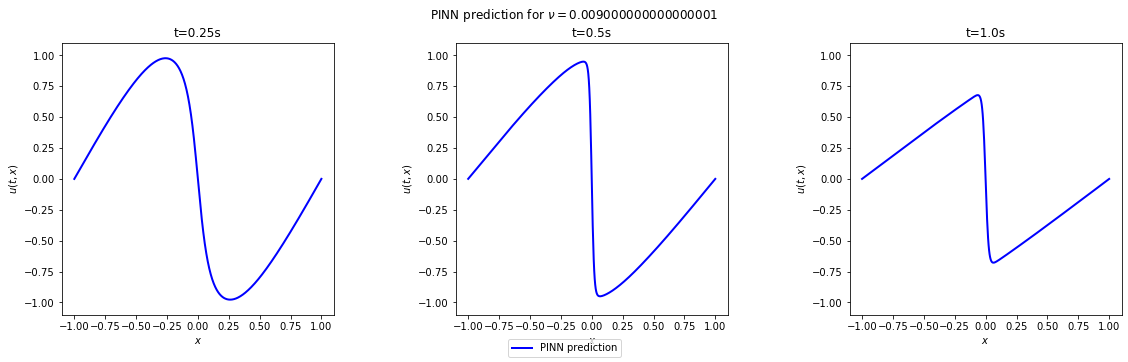

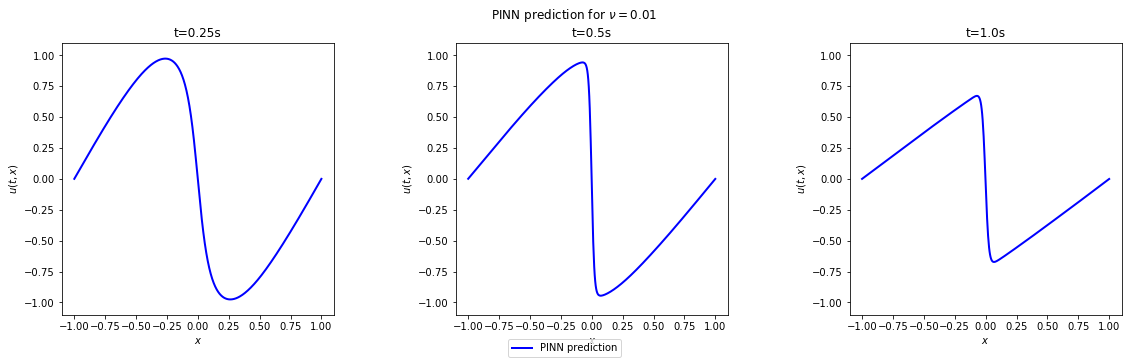

In [20]:
for visc in np.linspace(numin, numax, 10):

  fig, ax = plt.subplots(1, 3, figsize=(20, 5))

  all_times = [0.25, 0.5, 1.0]
  for i_t, end_time in enumerate(all_times):


      # solution en utilisant le PINN
      N = 500
      T = end_time * np.ones(N+1)
      xspace = np.linspace(lb[1], ub[1], N + 1)
      nuspace = visc * np.ones(N+1)
      Xgrid = np.vstack([T.flatten(),xspace.flatten(), nuspace.flatten()]).T
      upred = model(tf.cast(Xgrid,DTYPE))
      upred = tf.reshape(upred, (1,N+1))[0].numpy()

      # affichage
      title = "t={}s".format(end_time)
      ax[i_t].set_title(title)

      ax[i_t].plot(xspace, upred, 'b-', linewidth = 2, label="PINN prediction")

      ax[i_t].set_xlabel('$x$')
      ax[i_t].set_ylabel('$u(t,x)$')    
      ax[i_t].axis('square')
      ax[i_t].set_xlim([-1.1,1.1])
      ax[i_t].set_ylim([-1.1,1.1]);

  handles, labels = ax[-1].get_legend_handles_labels()
  fig.legend(handles, labels, loc='lower center', ncol=4);
  plt.suptitle(r"PINN prediction for $\nu=$" + str(visc))

In [26]:
model.save_weights("modeledeouf.h5")

# Avec une plage de viscosité plus grande 

In [26]:
numin = 5e-5
numax=  1e-2

# Lower bounds
lb = tf.constant([tmin, xmin, numin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax, numax], dtype=DTYPE)

In [27]:
X_r, X_data, u_data = gen_train_data(200_000,20_000,200_000)

In [28]:
model2 = PhysicsInformedNN(lb, ub)
model2.build(input_shape=(None,3))

# Initilize PINN solver
solver2 = PINNSolver(model2, X_r)

In [29]:
t0 = time()
try: 
  lr = 1e-3
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver2.solve_with_TFoptimizer(optim, X_data, u_data, N=4001)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 00000: loss = 6.03158057e-01
Iteration 00100: loss = 1.51152968e-01
Iteration 00200: loss = 1.23267479e-01
Iteration 00300: loss = 1.11030191e-01
Iteration 00400: loss = 9.60465968e-02
Iteration 00500: loss = 8.73362049e-02
Iteration 00600: loss = 8.04866403e-02
Iteration 00700: loss = 7.26084113e-02
Iteration 00800: loss = 6.54254854e-02
Iteration 00900: loss = 5.78158945e-02
Iteration 01000: loss = 4.88130488e-02
Iteration 01100: loss = 4.27905507e-02
Iteration 01200: loss = 3.93928885e-02
Iteration 01300: loss = 3.51871252e-02
Iteration 01400: loss = 3.26731838e-02
Iteration 01500: loss = 3.20842154e-02
Iteration 01600: loss = 2.87948120e-02
Iteration 01700: loss = 2.72028483e-02
Iteration 01800: loss = 2.54696235e-02
Iteration 01900: loss = 2.38984898e-02
Iteration 02000: loss = 2.25715153e-02
Iteration 02100: loss = 2.11967696e-02
Iteration 02200: loss = 1.96055733e-02
Iteration 02300: loss = 1.85307357e-02
Iteration 02400: loss = 1.99613236e-02
Iteration 02500: loss = 1

In [30]:
t0 = time()
try: 
  solver2.solve_with_ScipyOptimizer(X_data, u_data)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 04100: loss = 7.32570142e-03
Iteration 04200: loss = 5.49993943e-03
Iteration 04300: loss = 4.64498857e-03
Iteration 04400: loss = 4.08902485e-03
Iteration 04500: loss = 3.53889377e-03
Iteration 04600: loss = 3.03565385e-03
Iteration 04700: loss = 2.71680299e-03
Iteration 04800: loss = 2.42216745e-03
Iteration 04900: loss = 2.17612856e-03
Iteration 05000: loss = 1.99911348e-03
Iteration 05100: loss = 1.83268171e-03
Iteration 05200: loss = 1.67637458e-03
Iteration 05300: loss = 1.56900531e-03
Iteration 05400: loss = 1.46973517e-03
Iteration 05500: loss = 1.36484904e-03
Iteration 05600: loss = 1.26928941e-03
Iteration 05700: loss = 1.20398158e-03
Iteration 05800: loss = 1.12219423e-03
Iteration 05900: loss = 1.04812172e-03
Iteration 06000: loss = 9.89968888e-04
Iteration 06100: loss = 9.48116940e-04
Iteration 06200: loss = 9.00501327e-04
Iteration 06300: loss = 8.59633146e-04
Iteration 06400: loss = 8.18985165e-04
Iteration 06500: loss = 7.94226595e-04

Training time: 840.00820

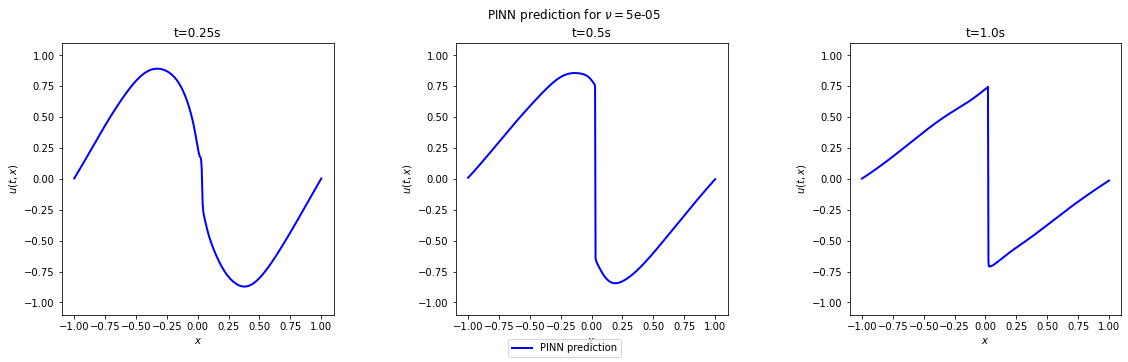

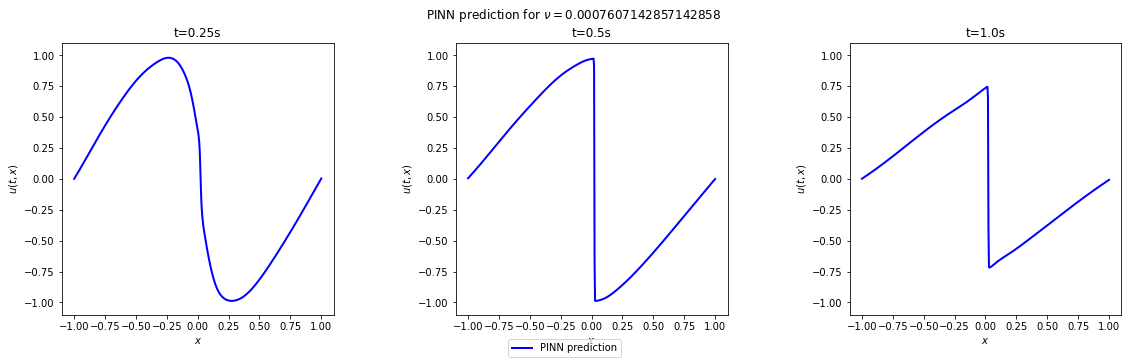

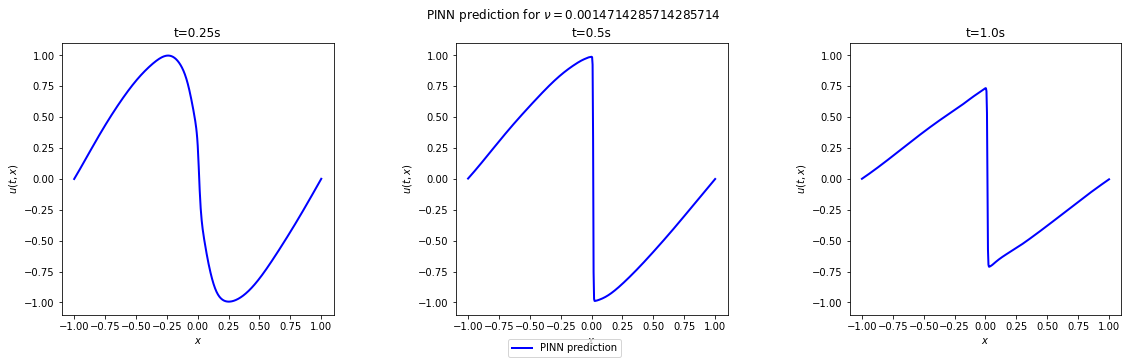

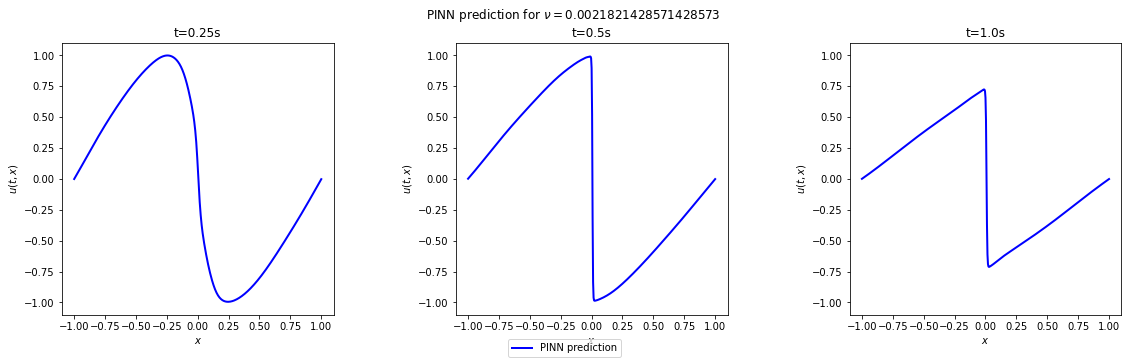

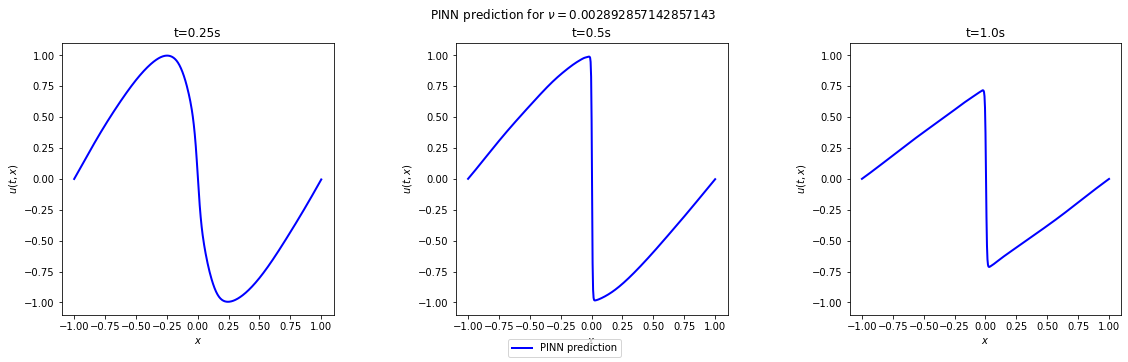

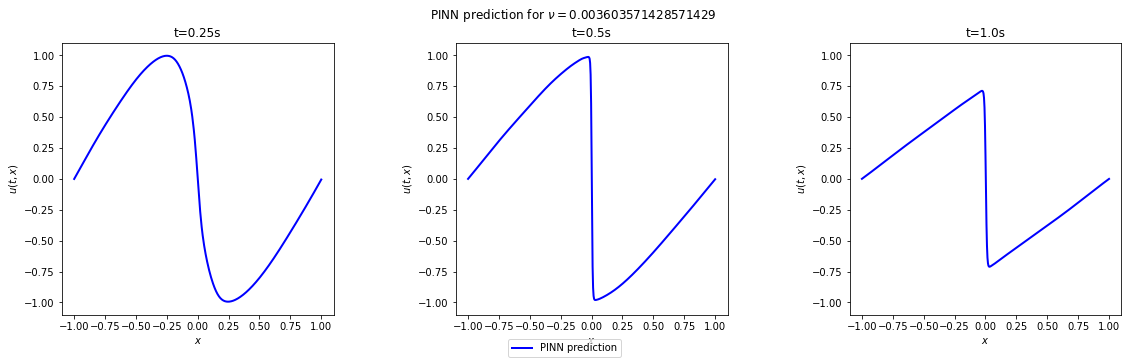

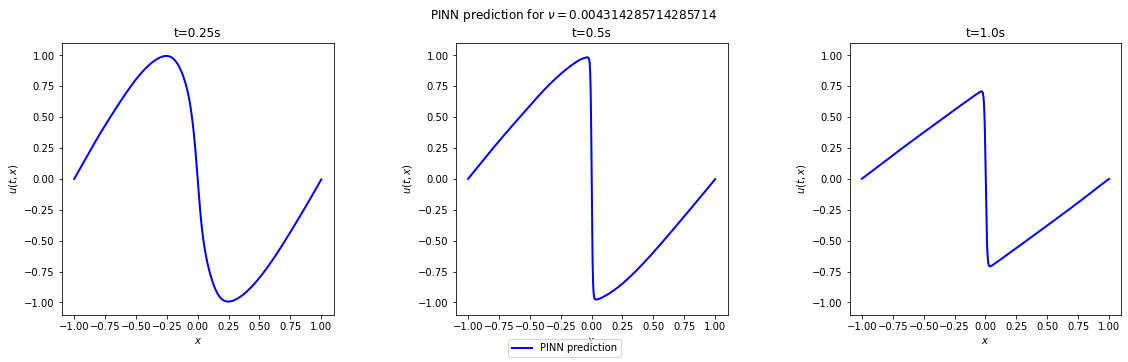

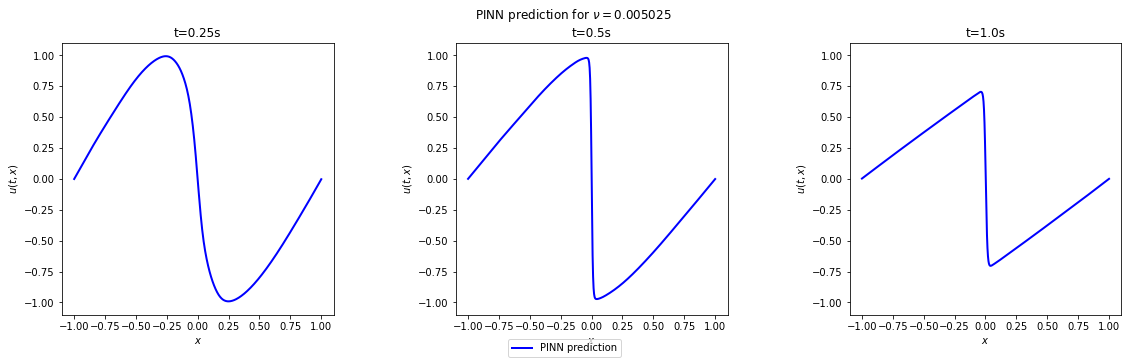

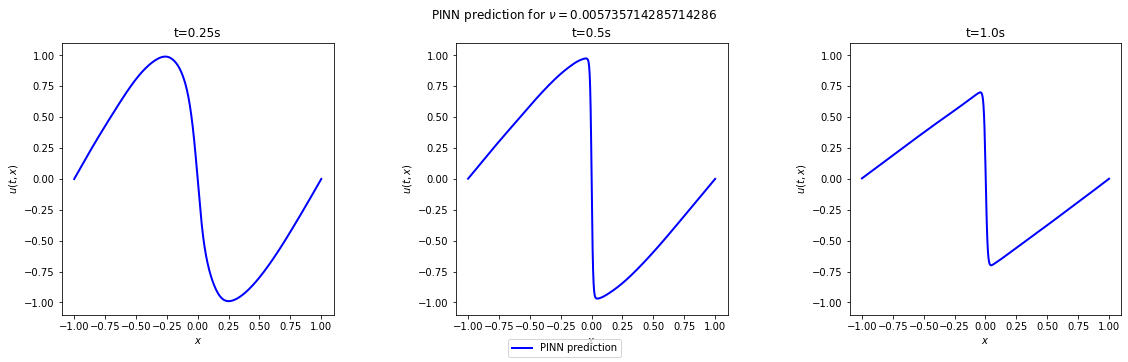

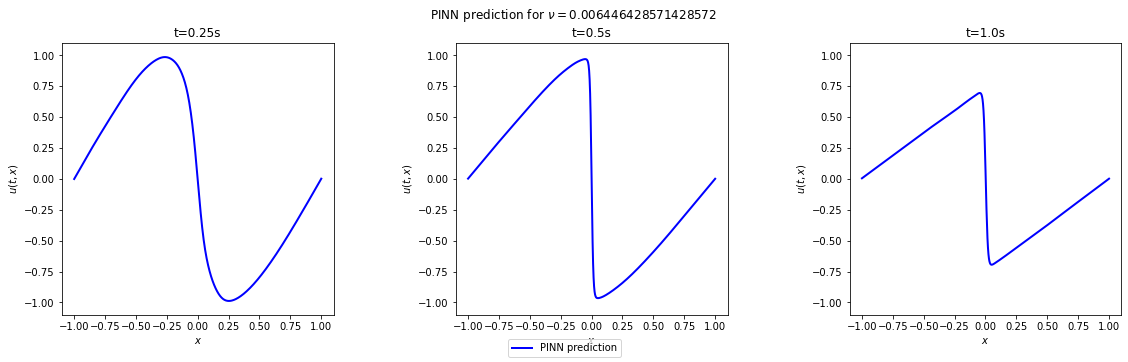

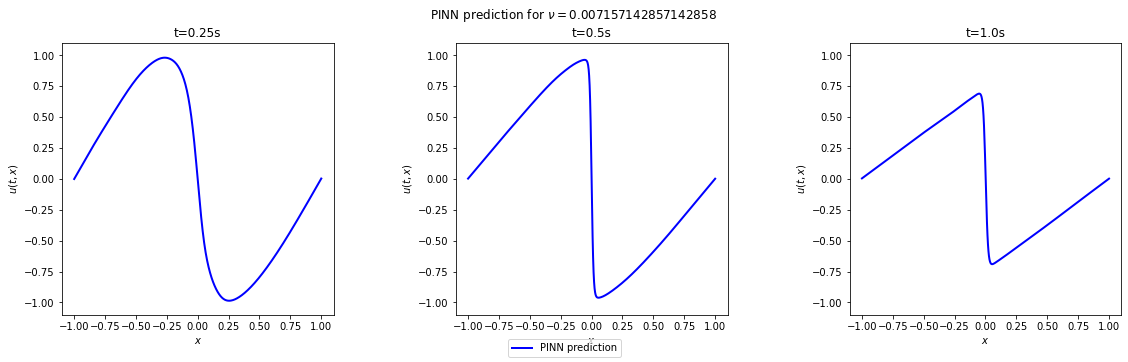

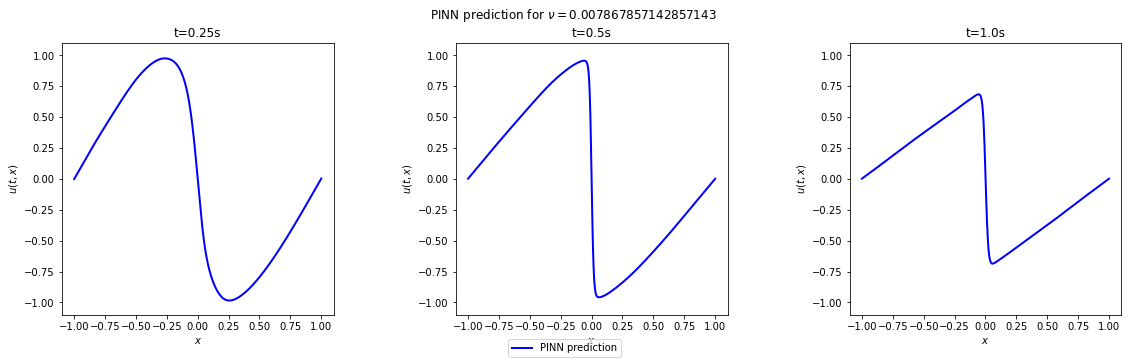

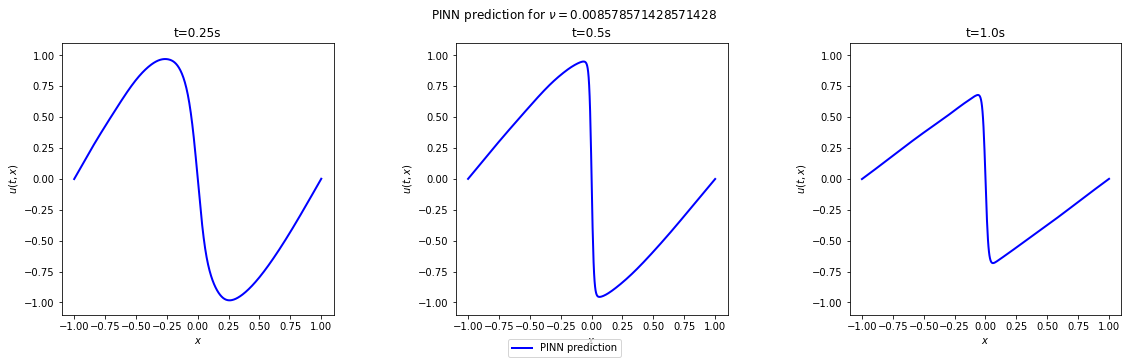

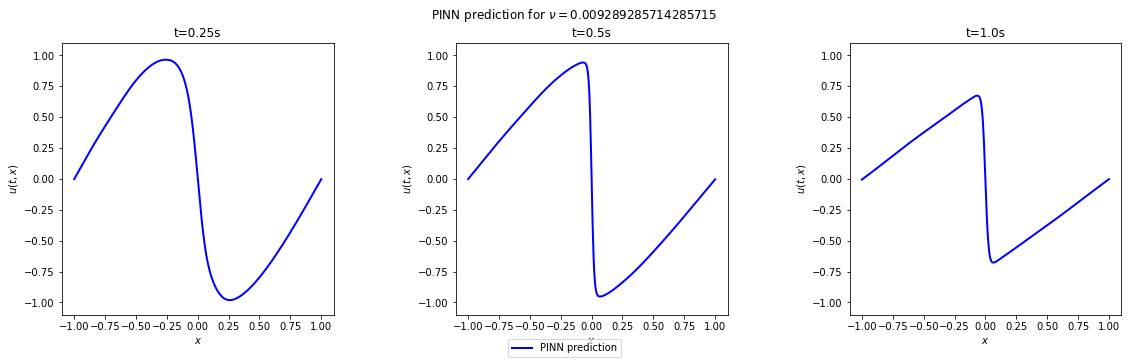

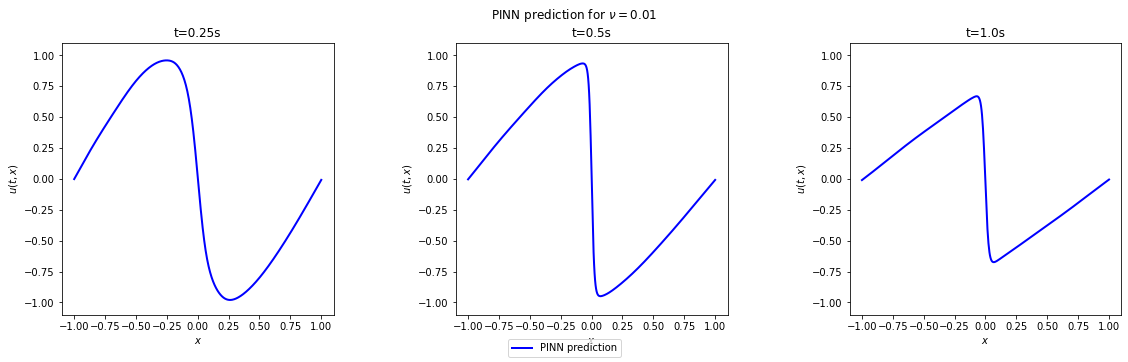

In [31]:
for visc in np.linspace(numin, numax, 15):

  fig, ax = plt.subplots(1, 3, figsize=(20, 5))

  all_times = [0.25, 0.5, 1.0]
  for i_t, end_time in enumerate(all_times):


      # solution en utilisant le PINN
      N = 500
      T = end_time * np.ones(N+1)
      xspace = np.linspace(lb[1], ub[1], N + 1)
      nuspace = visc * np.ones(N+1)
      Xgrid = np.vstack([T.flatten(),xspace.flatten(), nuspace.flatten()]).T
      upred = model2(tf.cast(Xgrid,DTYPE))
      upred = tf.reshape(upred, (1,N+1))[0].numpy()

      # affichage
      title = "t={}s".format(end_time)
      ax[i_t].set_title(title)

      ax[i_t].plot(xspace, upred, 'b-', linewidth = 2, label="PINN prediction")

      ax[i_t].set_xlabel('$x$')
      ax[i_t].set_ylabel('$u(t,x)$')    
      ax[i_t].axis('square')
      ax[i_t].set_xlim([-1.1,1.1])
      ax[i_t].set_ylim([-1.1,1.1]);

  handles, labels = ax[-1].get_legend_handles_labels()
  fig.legend(handles, labels, loc='lower center', ncol=4);
  plt.suptitle(r"PINN prediction for $\nu=$" + str(visc))

In [33]:
model.save_weights("model1.h5")

In [35]:
model2.save_weights("model2.h5")

In [ ]:
t0 = time()
try: 
  solver2.solve_with_ScipyOptimizer(X_data, u_data)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 03100: loss = 9.60272271e-04
Iteration 03200: loss = 9.44780593e-04
Iteration 03300: loss = 9.19987855e-04
Iteration 03400: loss = 8.99024948e-04
Iteration 03500: loss = 8.81724292e-04
Iteration 03600: loss = 8.62036250e-04
Iteration 03700: loss = 8.47232935e-04
Iteration 03800: loss = 8.33495520e-04
Iteration 03900: loss = 8.16865708e-04
Iteration 04000: loss = 7.99564819e-04
Iteration 04100: loss = 7.89812650e-04
Iteration 04200: loss = 7.74505781e-04
Iteration 04300: loss = 7.64260010e-04
Iteration 04400: loss = 7.49912055e-04
Iteration 04500: loss = 7.33147608e-04
Iteration 04600: loss = 7.18804018e-04
Iteration 04700: loss = 7.05829414e-04
Iteration 04800: loss = 6.94593356e-04
Iteration 04900: loss = 6.83750259e-04
Iteration 05000: loss = 6.75180228e-04
Iteration 05100: loss = 6.67447166e-04
Iteration 05200: loss = 6.60523539e-04
Iteration 05300: loss = 6.53873081e-04
Iteration 05400: loss = 6.48079265e-04
Iteration 05500: loss = 6.43275795e-04
Iteration 05600: loss = 6

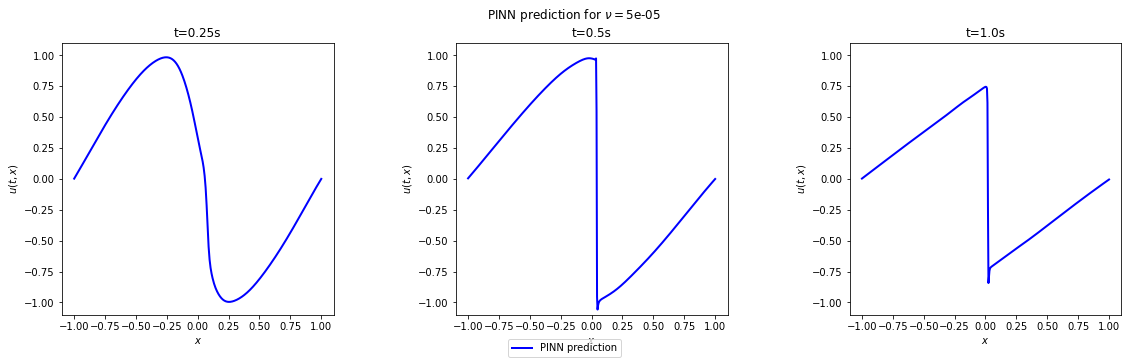

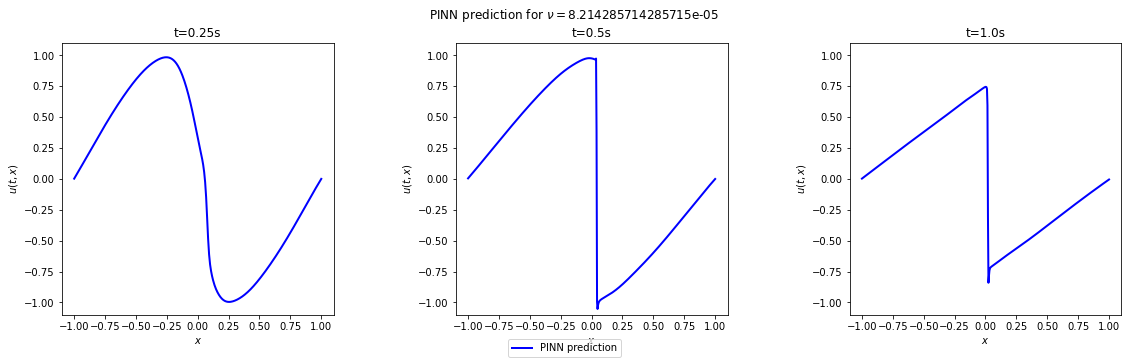

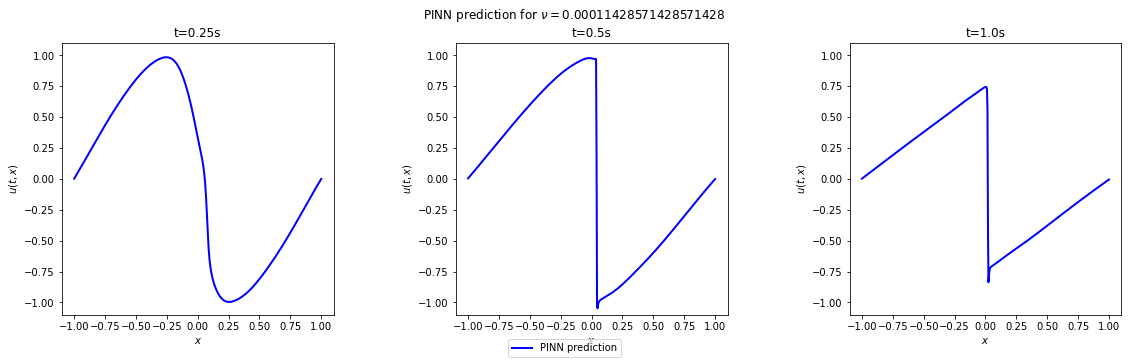

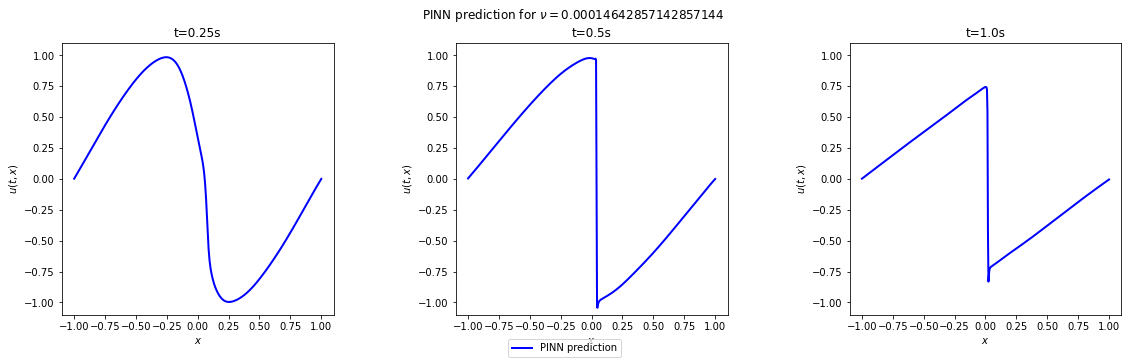

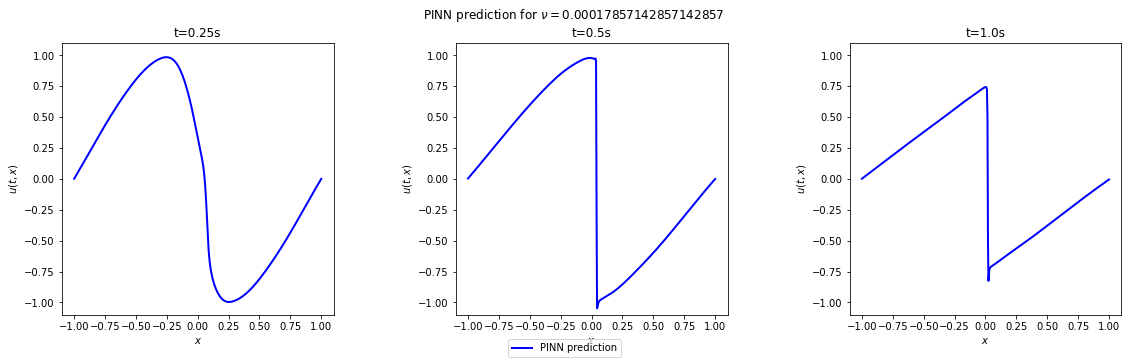

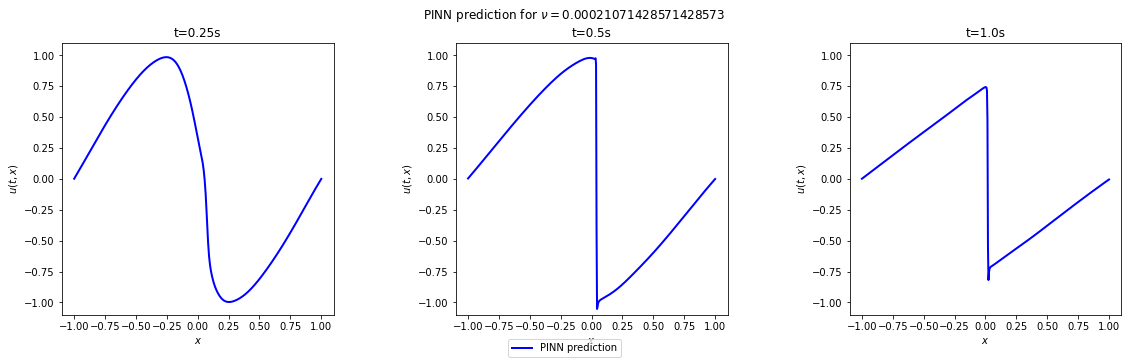

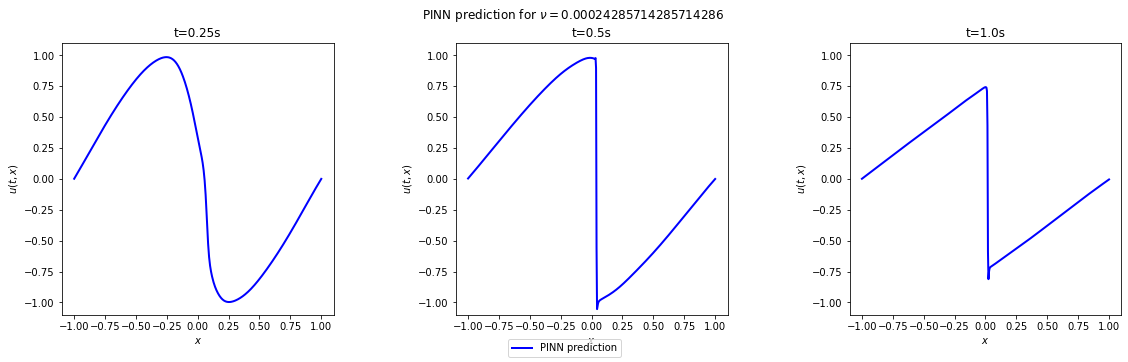

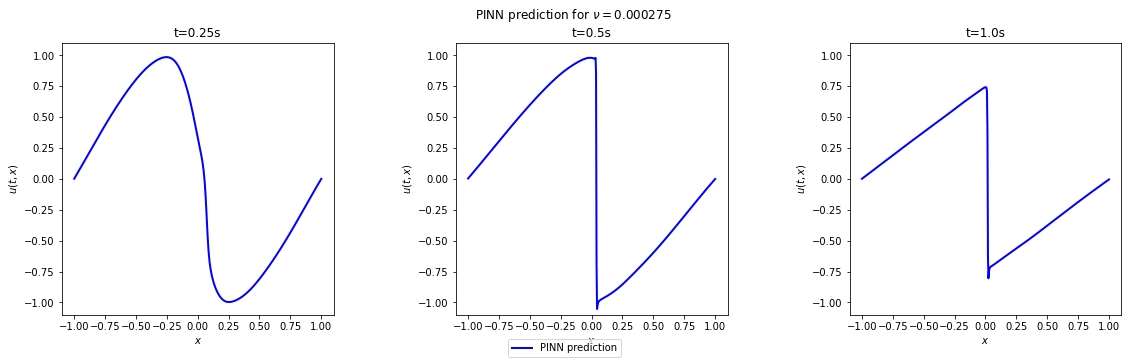

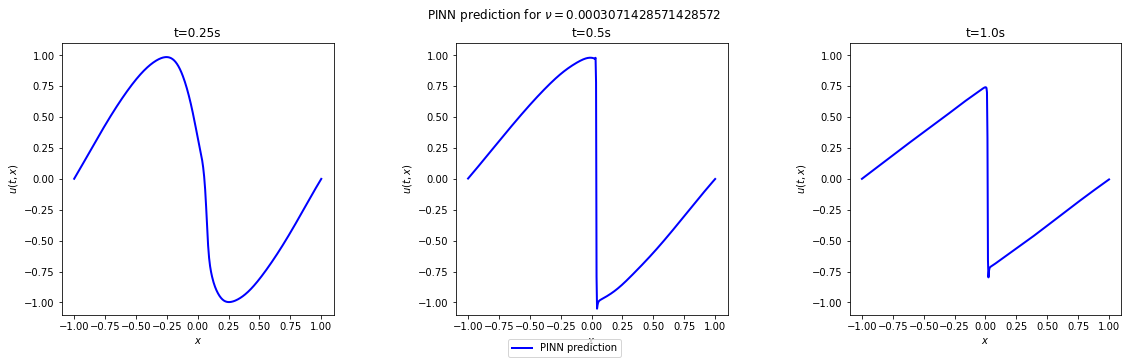

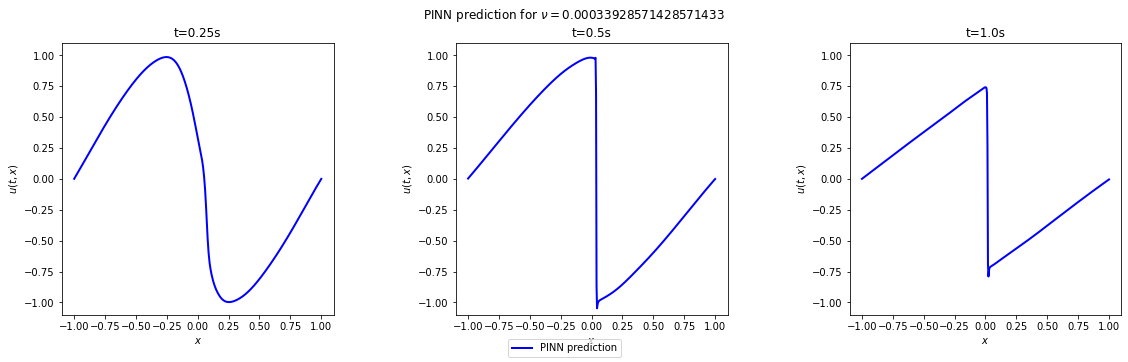

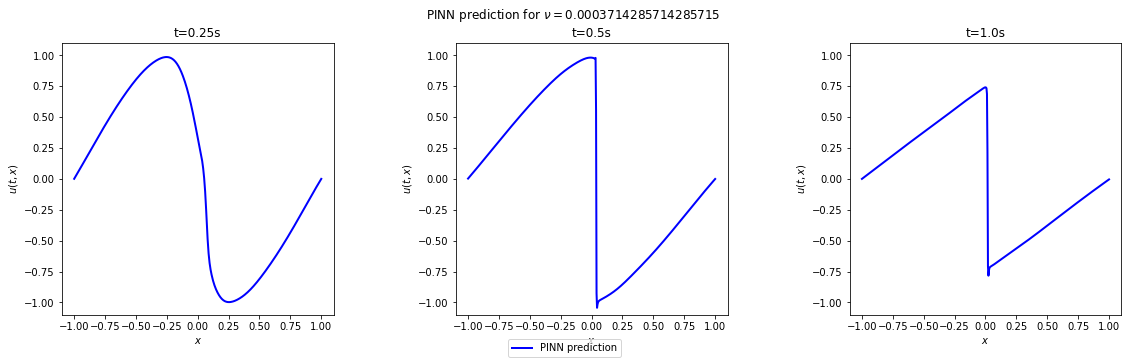

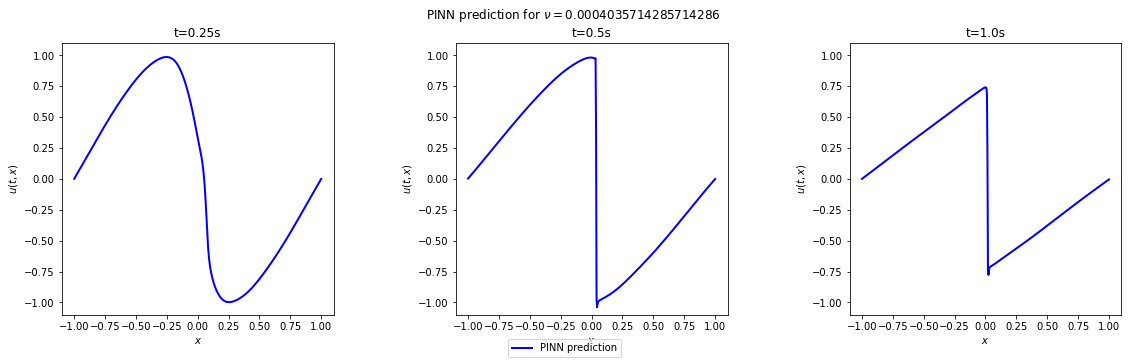

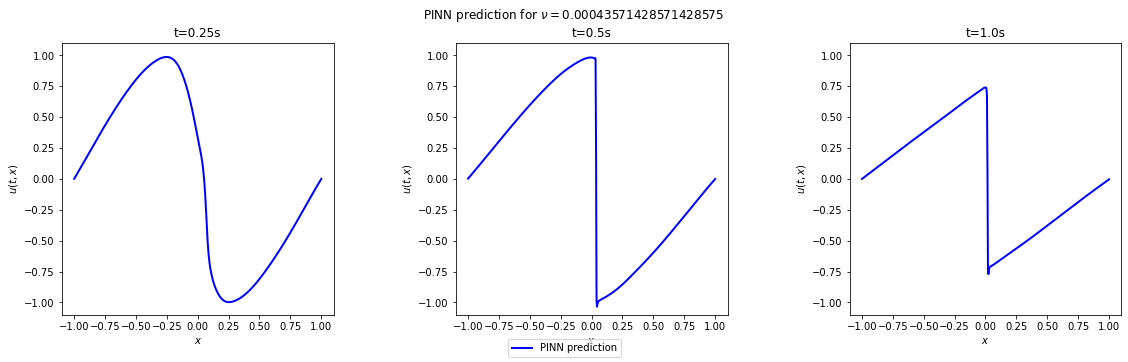

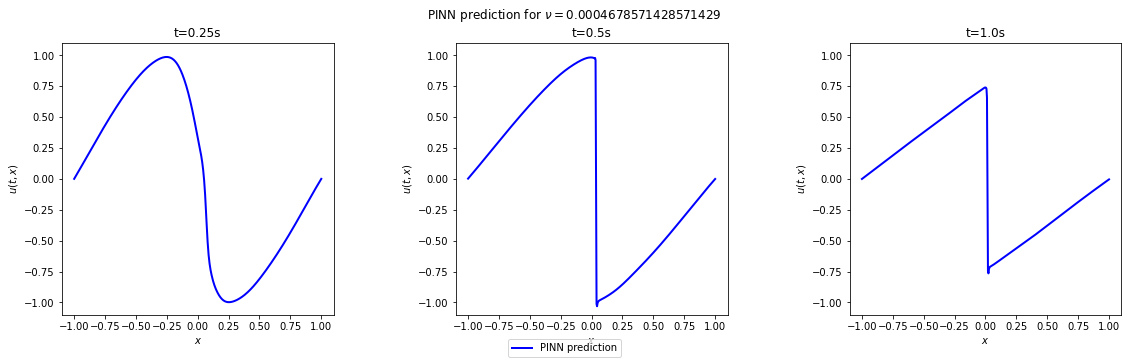

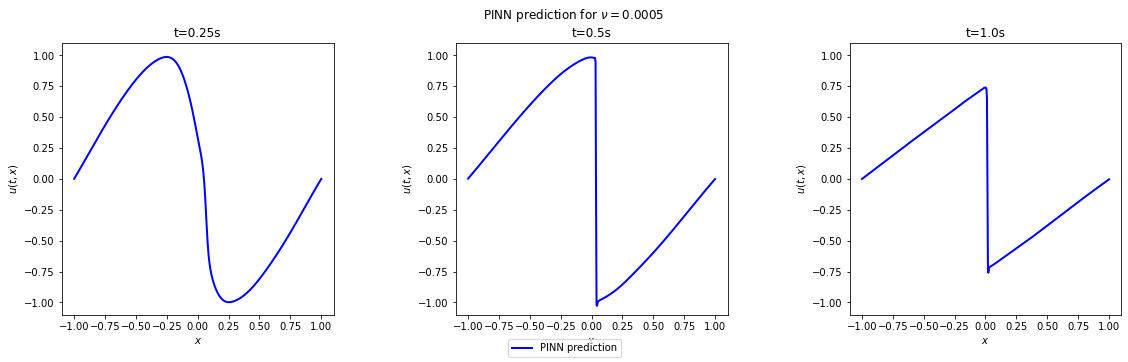

In [ ]:
for visc in np.linspace(numin, 10*numin, 15):

  fig, ax = plt.subplots(1, 3, figsize=(20, 5))

  all_times = [0.25, 0.5, 1.0]
  for i_t, end_time in enumerate(all_times):


      # solution en utilisant le PINN
      N = 500
      T = end_time * np.ones(N+1)
      xspace = np.linspace(lb[1], ub[1], N + 1)
      nuspace = visc * np.ones(N+1)
      Xgrid = np.vstack([T.flatten(),xspace.flatten(), nuspace.flatten()]).T
      upred = model2(tf.cast(Xgrid,DTYPE))
      upred = tf.reshape(upred, (1,N+1))[0].numpy()

      # affichage
      title = "t={}s".format(end_time)
      ax[i_t].set_title(title)

      ax[i_t].plot(xspace, upred, 'b-', linewidth = 2, label="PINN prediction")

      ax[i_t].set_xlabel('$x$')
      ax[i_t].set_ylabel('$u(t,x)$')    
      ax[i_t].axis('square')
      ax[i_t].set_xlim([-1.1,1.1])
      ax[i_t].set_ylim([-1.1,1.1]);

  handles, labels = ax[-1].get_legend_handles_labels()
  fig.legend(handles, labels, loc='lower center', ncol=4);
  plt.suptitle(r"PINN prediction for $\nu=$" + str(visc))